# Milestone 1: Setup and Dataset
**Generative Project (Text to Image) · IE 7615**

This notebook builds the foundation for a text to image model: a verified Stable Diffusion setup, a clean image caption dataset, a text → embedding pipeline, and five baseline generations.

| Section | Milestone task |
|---|---|
| 1. Setup | Environment: PyTorch + Diffusers + CLIP |
| 2. Model architecture | Model choice and architecture checks |
| 3. Dataset | Choose dataset, clean and preprocess 1k to 5k pairs |
| 4. Text → embedding | Baseline embedding pipeline |
| 5. Sample generations | 5 prompt → image test runs |
| 6. Summary | Key numbers and next steps |

**How to run:** GPU runtime (Colab T4 or better), top to bottom. Raw data is saved to `data/` and all outputs to `outputs/`. Keep both folders out of git.

## 1. Setup

In [1]:
# Colab ships with PyTorch; this adds the Hugging Face libraries
!pip install -q diffusers transformers accelerate

In [2]:
import json
import random
import textwrap
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm

import diffusers
import transformers
from diffusers import DPMSolverMultistepScheduler, StableDiffusionPipeline
from transformers import CLIPModel, CLIPProcessor

# ---------------- Config ----------------
SEED = 42

# Models
SD_MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
CLIP_MODEL_ID = "openai/clip-vit-large-patch14"  # same text encoder SD v1.5 uses

# Data
N_PAIRS = 2000       # subset size (milestone range: 1k to 5k)
IMAGE_SIZE = 512     # SD v1.5 native resolution
MIN_SIDE = 320       # skip small images (limits upscaling to 1.6x)
MIN_WORDS, MAX_WORDS = 5, 30

# Embeddings and evaluation
EMBED_BATCH = 64
N_RETRIEVAL = 500

# Generation
NUM_STEPS = 25
GUIDANCE = 7.5

# Paths
DATA_DIR = Path("data/coco")          # raw download
OUT_DIR = Path("outputs/milestone1")  # processed images, manifest, embeddings, samples

In [3]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(SEED)

print(f"torch {torch.__version__} | diffusers {diffusers.__version__} | transformers {transformers.__version__}")
print(f"device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))

torch 2.11.0+cu130 | diffusers 0.42.1 | transformers 5.22.0
device: cuda (Tesla T4)


## 2. Model architecture

We use **Stable Diffusion v1.5**, a latent diffusion model. Generation runs in a compressed latent space and is guided by a frozen CLIP text encoder.

| Component | Role | Output shape (512×512) |
|---|---|---|
| Tokenizer | Prompt → token ids (padded or truncated to 77) | (77,) |
| Text encoder (CLIP ViT-L/14, frozen) | Token ids → contextual token embeddings | (77, 768) |
| UNet | Predicts noise in the latent; reads the text through cross attention | latent (4, 64, 64) |
| VAE | Decodes the final latent to pixels (8x upsampling) | (3, 512, 512) |
| Scheduler | Sets the denoising steps (DPM Solver++ here) | n/a |

**Flow:** prompt → tokenizer → text encoder → (77 × 768) → UNet cross attention ⟲ noisy latent, repeated for each step → VAE decoder → image.

The text → embedding pipeline in Section 4 is exactly this conditioning stage. We also load the full CLIP model because its image tower is needed for retrieval checks and CLIP scores. The checks below confirm the shapes line up and that the standalone CLIP text encoder is identical to the one inside Stable Diffusion.

In [4]:
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_ID, torch_dtype=DTYPE).to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_ID)
tokenizer = clip_processor.tokenizer

pipe = StableDiffusionPipeline.from_pretrained(SD_MODEL_ID, torch_dtype=DTYPE).to(DEVICE)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

In [5]:
def n_params(module):
    return sum(p.numel() for p in module.parameters()) / 1e6


arch = pd.DataFrame(
    [
        ("Text encoder", type(pipe.text_encoder).__name__, n_params(pipe.text_encoder)),
        ("UNet", type(pipe.unet).__name__, n_params(pipe.unet)),
        ("VAE", type(pipe.vae).__name__, n_params(pipe.vae)),
    ],
    columns=["component", "class", "params (M)"],
).round(1)
display(arch)

# Shape contracts between components
assert pipe.tokenizer.model_max_length == 77
assert pipe.text_encoder.config.hidden_size == 768
assert pipe.unet.config.cross_attention_dim == pipe.text_encoder.config.hidden_size

latent_side = IMAGE_SIZE // pipe.vae_scale_factor
print(f"Text conditioning: (77, {pipe.text_encoder.config.hidden_size})")
print(f"Latent: ({pipe.unet.config.in_channels}, {latent_side}, {latent_side})")
print(f"Scheduler: {type(pipe.scheduler).__name__}")

,component,class,params (M)
0,Text encoder,CLIPTextModel,123.1
1,UNet,UNet2DConditionModel,859.5
2,VAE,AutoencoderKL,83.7


Text conditioning: (77, 768)
Latent: (4, 64, 64)
Scheduler: DPMSolverMultistepScheduler


In [6]:
# The standalone CLIP text encoder must match the one inside SD
test_prompt = ["a dog running on the beach"]
tok_args = dict(padding="max_length", max_length=77, truncation=True, return_tensors="pt")

ids = tokenizer(test_prompt, **tok_args).input_ids
assert torch.equal(ids, pipe.tokenizer(test_prompt, **tok_args).input_ids), "Tokenizers differ"

with torch.no_grad():
    ours = clip_model.text_model(input_ids=ids.to(DEVICE)).last_hidden_state
    theirs = pipe.text_encoder(input_ids=ids.to(DEVICE)).last_hidden_state

max_diff = (ours - theirs).abs().max().item()
assert max_diff < 1e-2, "Text encoders differ"
print(f"Token ids match. Max embedding difference vs SD text encoder: {max_diff:.1e}")

Token ids match. Max embedding difference vs SD text encoder: 0.0e+00


## 3. Dataset: COCO 2017 captions

**Why COCO val2017:** 5,000 images with about 5 human written captions each, around 1 GB, and a standard benchmark for text to image models. We keep a clean subset of `N_PAIRS` pairs.

**Cleaning steps**
1. Normalize caption text (whitespace, trailing period).
2. Drop captions outside 5 to 30 words or over CLIP's 77 token limit.
3. Drop duplicate captions for the same image.
4. Keep one caption per image: the most descriptive (longest) valid one.
5. Drop small or unreadable images and convert everything to RGB.
6. Resize the short side to 512 and center crop to 512 × 512.

In [7]:
COCO_FILES = {
    "val2017": "http://images.cocodataset.org/zips/val2017.zip",
    "annotations": "http://images.cocodataset.org/annotations/annotations_trainval2017.zip",
}

DATA_DIR.mkdir(parents=True, exist_ok=True)
for folder, url in COCO_FILES.items():
    if (DATA_DIR / folder).exists():
        continue  # already downloaded
    zip_path = DATA_DIR / f"{folder}.zip"
    torch.hub.download_url_to_file(url, str(zip_path))
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(DATA_DIR)
    zip_path.unlink()  # free disk space

In [8]:
with open(DATA_DIR / "annotations" / "captions_val2017.json") as f:
    coco = json.load(f)

images = pd.DataFrame(coco["images"])[["id", "file_name", "width", "height"]].rename(columns={"id": "image_id"})
captions = pd.DataFrame(coco["annotations"])[["image_id", "caption"]]
raw = captions.merge(images, on="image_id")

print(f"Raw data: {raw['image_id'].nunique():,} images, {len(raw):,} captions")

Raw data: 5,000 images, 25,014 captions


In [9]:
def normalize_caption(text):
    text = " ".join(text.split())  # collapse spaces and newlines
    return text.rstrip(" .")


df = raw.copy()
df["caption"] = df["caption"].map(normalize_caption)
df["n_words"] = df["caption"].str.split().str.len()
df["n_tokens"] = [len(ids) for ids in tokenizer(df["caption"].tolist()).input_ids]
funnel = {"Raw captions": len(df)}

# Length limits: drop fragments and anything CLIP would truncate
df = df[df["n_words"].between(MIN_WORDS, MAX_WORDS) & (df["n_tokens"] <= tokenizer.model_max_length)]
funnel["Within length limits"] = len(df)

# Duplicate captions for the same image (case insensitive)
df = df[~df.assign(key=df["caption"].str.lower()).duplicated(["image_id", "key"])]
funnel["After deduplication"] = len(df)

# One caption per image: the longest valid one
df = df.sort_values("n_words", ascending=False, kind="stable").drop_duplicates("image_id")
funnel["One caption per image"] = len(df)

# Large enough to crop to 512 without heavy upscaling
df = df[df[["width", "height"]].min(axis=1) >= MIN_SIDE]
funnel[f"Short side ≥ {MIN_SIDE} px"] = len(df)

In [10]:
def load_rgb(path):
    """Open an image as RGB, or return None if the file is unreadable."""
    try:
        with Image.open(path) as img:
            return img.convert("RGB")
    except (OSError, ValueError):
        return None


def resize_center_crop(img, size):
    scale = size / min(img.size)
    img = img.resize((round(img.width * scale), round(img.height * scale)), Image.Resampling.BICUBIC)
    left, top = (img.width - size) // 2, (img.height - size) // 2
    return img.crop((left, top, left + size, top + size))


IMG_OUT = OUT_DIR / "images"
IMG_OUT.mkdir(parents=True, exist_ok=True)

records = []
for row in tqdm(df.sample(frac=1, random_state=SEED).itertuples(), total=N_PAIRS, desc="Processing images"):
    if len(records) == N_PAIRS:
        break
    out_path = IMG_OUT / row.file_name
    if not out_path.exists():  # skip work on reruns
        img = load_rgb(DATA_DIR / "val2017" / row.file_name)
        if img is None:
            continue
        resize_center_crop(img, IMAGE_SIZE).save(out_path, quality=95)
    records.append({"image_id": row.image_id, "image_path": str(out_path), "caption": row.caption})

manifest = pd.DataFrame(records)
manifest.to_csv(OUT_DIR / "manifest.csv", index=False)

Processing images:   0%|          | 0/2000 [00:00<?, ?it/s]

In [11]:
funnel["Final processed pairs"] = len(manifest)
display(pd.Series(funnel, name="count").to_frame())

print("Caption length (words):")
print(manifest["caption"].str.split().str.len().describe().round(1).to_string())

,count
Raw captions,25014
Within length limits,25003
After deduplication,24989
One caption per image,5000
Short side ≥ 320 px,4879
Final processed pairs,2000


Caption length (words):
count    2000.0
mean       13.2
std         2.8
min         8.0
25%        11.0
50%        13.0
75%        14.0
max        30.0


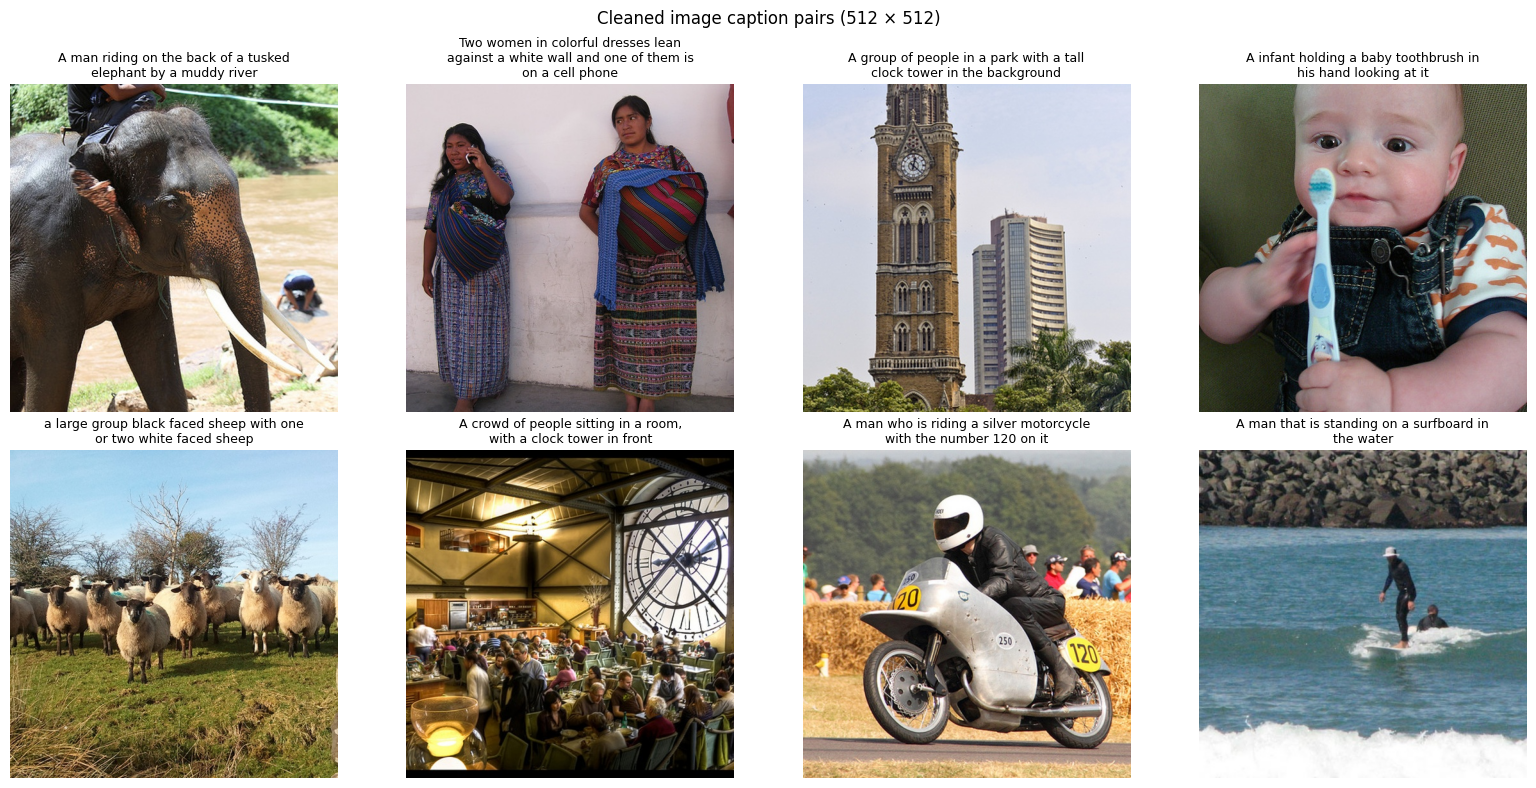

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, row in zip(axes.flat, manifest.sample(8, random_state=SEED).itertuples()):
    ax.imshow(Image.open(row.image_path))
    ax.set_title(textwrap.fill(row.caption, 40), fontsize=9)
    ax.axis("off")
fig.suptitle("Cleaned image caption pairs (512 × 512)")
plt.tight_layout()
plt.show()

A minimal PyTorch dataset for the next milestone. Pixels are scaled to [-1, 1], the input range the SD VAE expects.

In [13]:
class CaptionImageDataset(torch.utils.data.Dataset):
    def __init__(self, manifest):
        self.items = manifest.reset_index(drop=True)

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        row = self.items.iloc[i]
        pixels = np.asarray(Image.open(row.image_path), dtype=np.float32) / 127.5 - 1.0
        return torch.from_numpy(pixels).permute(2, 0, 1), row.caption


dataset = CaptionImageDataset(manifest)
x, caption = dataset[0]
print(f"{len(dataset)} pairs | image tensor {tuple(x.shape)}, range [{x.min():.1f}, {x.max():.1f}]")

2000 pairs | image tensor (3, 512, 512), range [-1.0, 1.0]


## 4. Text → embedding pipeline

Each caption is tokenized (padded or truncated to 77 tokens) and passed through the CLIP text encoder. One pass gives two outputs:

* **Token embeddings (77 × 768):** the last hidden state. This is what the SD UNet attends to.
* **Caption embedding (768):** the end of text token, projected into CLIP's shared image text space and L2 normalized. Used for similarity, retrieval, and CLIP scores.

In [14]:
@torch.no_grad()
def encode_text(texts, batch_size=EMBED_BATCH):
    """Return token embeddings [N, 77, 768] and normalized caption embeddings [N, 768]."""
    token_embeds, text_embeds = [], []
    for i in tqdm(range(0, len(texts), batch_size), desc="Encoding text", disable=len(texts) <= batch_size):
        ids = tokenizer(texts[i : i + batch_size], **tok_args).input_ids.to(DEVICE)
        out = clip_model.text_model(input_ids=ids)
        token_embeds.append(out.last_hidden_state.cpu())
        text_embeds.append(clip_model.text_projection(out.pooler_output).cpu())
    text_embeds = torch.cat(text_embeds)
    return torch.cat(token_embeds), text_embeds / text_embeds.norm(dim=-1, keepdim=True)


@torch.no_grad()
def encode_images(images, batch_size=EMBED_BATCH):
    """Return normalized CLIP image embeddings [N, 768] from file paths or PIL images."""
    feats = []
    for i in tqdm(range(0, len(images), batch_size), desc="Encoding images", disable=len(images) <= batch_size):
        batch = [im if isinstance(im, Image.Image) else Image.open(im).convert("RGB") for im in images[i : i + batch_size]]
        pixels = clip_processor(images=batch, return_tensors="pt").pixel_values.to(DEVICE, DTYPE)
        out = clip_model.vision_model(pixel_values=pixels)
        feats.append(clip_model.visual_projection(out.pooler_output).cpu())
    feats = torch.cat(feats)
    return feats / feats.norm(dim=-1, keepdim=True)

In [15]:
captions_list = manifest["caption"].tolist()
token_embeds, text_embeds = encode_text(captions_list)

torch.save(
    {
        "image_id": manifest["image_id"].tolist(),
        "caption": captions_list,
        "token_embeds": token_embeds,  # UNet conditioning
        "text_embeds": text_embeds,    # CLIP joint space
    },
    OUT_DIR / "text_embeddings.pt",
)
print(f"token_embeds {tuple(token_embeds.shape)} | text_embeds {tuple(text_embeds.shape)}")

Encoding text:   0%|          | 0/32 [00:00<?, ?it/s]

token_embeds (2000, 77, 768) | text_embeds (2000, 768)


**Sanity check 1: semantic similarity.** Captions that describe the same scene should score higher with each other than with unrelated captions.

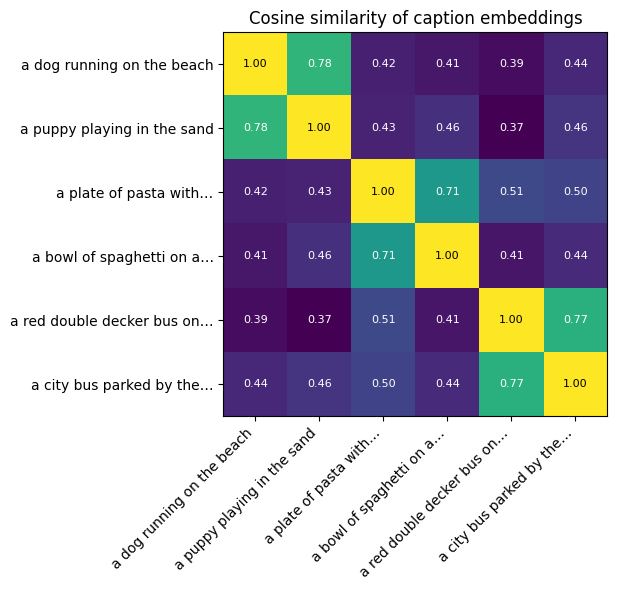

In [16]:
probe = [
    "a dog running on the beach",
    "a puppy playing in the sand",
    "a plate of pasta with tomato sauce",
    "a bowl of spaghetti on a table",
    "a red double decker bus on a city street",
    "a city bus parked by the curb",
]
_, probe_embeds = encode_text(probe)
sim = (probe_embeds.float() @ probe_embeds.float().T).numpy()

labels = [textwrap.shorten(p, 28, placeholder="…") for p in probe]
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(sim, cmap="viridis")
ax.set_xticks(range(len(probe)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(probe)), labels)
for i in range(len(probe)):
    for j in range(len(probe)):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="black" if sim[i, j] > 0.8 else "white")
ax.set_title("Cosine similarity of caption embeddings")
plt.tight_layout()
plt.show()

**Sanity check 2: text → image retrieval.** For each caption, rank all images by similarity and check whether its own image lands in the top k. Random chance at R@1 is 1 / N_RETRIEVAL (0.2%).

In [17]:
eval_set = manifest.iloc[:N_RETRIEVAL]
image_embeds = encode_images(eval_set["image_path"].tolist())

sims = text_embeds[:N_RETRIEVAL].float() @ image_embeds.float().T
ranks = (sims > sims.diag()[:, None]).sum(dim=1)  # 0 means the true image ranked first

recall = {k: (ranks < k).float().mean().item() for k in (1, 5, 10)}
for k, r in recall.items():
    print(f"Recall@{k}: {r:.1%}")

Encoding images:   0%|          | 0/8 [00:00<?, ?it/s]

Recall@1: 68.2%
Recall@5: 91.0%
Recall@10: 97.2%


## 5. Sample generations

Five prompts through pretrained SD v1.5, with no fine tuning yet. Three are captions from our dataset (shown next to the real photo) and two are new prompts that test generalization. Settings: DPM Solver++ scheduler, `NUM_STEPS` steps, guidance `GUIDANCE`, fixed seed per image.

Each image gets a **CLIP score**: 100 × cosine similarity between the image and prompt embeddings. Higher means better prompt alignment.

In [18]:
SAMPLES_DIR = OUT_DIR / "samples"
SAMPLES_DIR.mkdir(parents=True, exist_ok=True)

from_data = manifest.sample(3, random_state=SEED + 1)
prompts = from_data["caption"].tolist() + [
    "a watercolor painting of a lighthouse on a cliff at sunset",
    "a red bicycle leaning against a brick wall on a rainy street",
]
sources = ["dataset"] * 3 + ["novel"] * 2
references = from_data["image_path"].tolist() + [None, None]

generated, seconds = [], []
for i, prompt in enumerate(tqdm(prompts, desc="Generating")):
    generator = torch.Generator(device=DEVICE).manual_seed(SEED + i)
    start = time.perf_counter()
    image = pipe(
        prompt,
        num_inference_steps=NUM_STEPS,
        guidance_scale=GUIDANCE,
        height=IMAGE_SIZE,
        width=IMAGE_SIZE,
        generator=generator,
    ).images[0]
    seconds.append(time.perf_counter() - start)
    image.save(SAMPLES_DIR / f"sample_{i + 1}.png")
    generated.append(image)

_, prompt_embeds = encode_text(prompts)
cosine = (encode_images(generated).float() * prompt_embeds.float()).sum(dim=-1)
clip_scores = (100 * cosine.clamp(min=0)).tolist()

Generating:   0%|          | 0/5 [00:00<?, ?it/s]

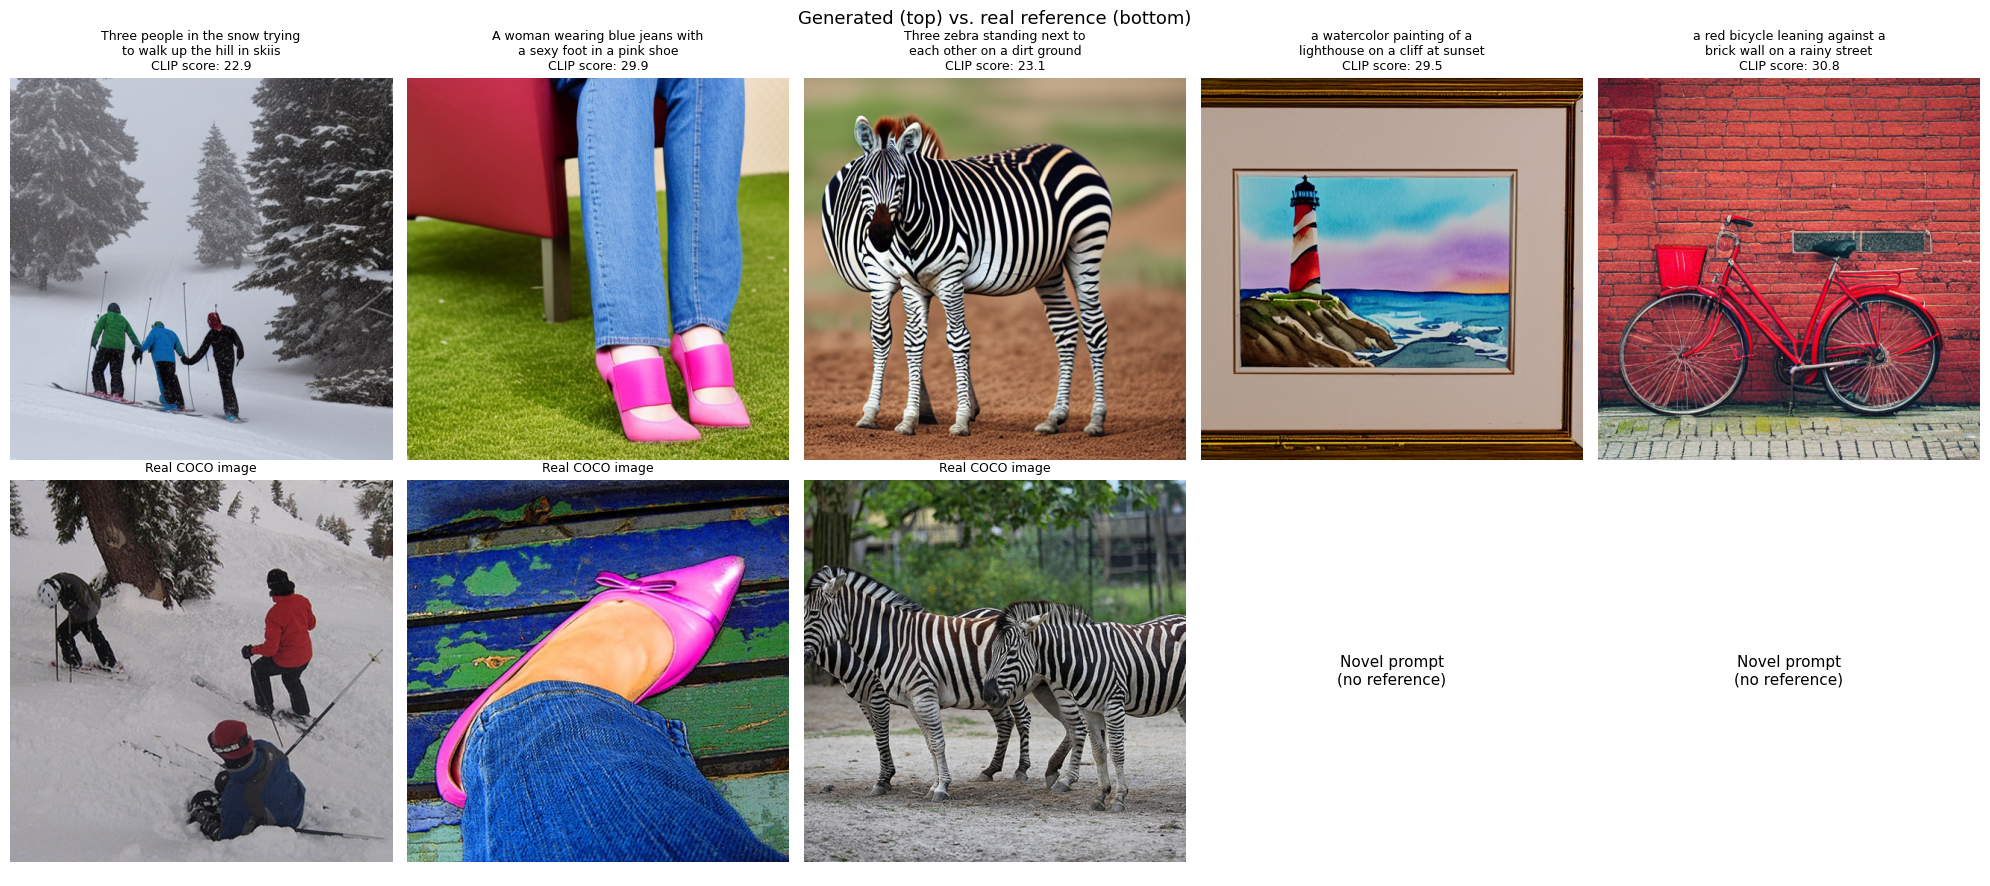

,prompt,source,clip_score,seconds
0,Three people in the snow trying to walk up the...,dataset,22.91,4.42
1,A woman wearing blue jeans with a sexy foot in...,dataset,29.91,3.86
2,Three zebra standing next to each other on a d...,dataset,23.13,3.90
3,a watercolor painting of a lighthouse on a cli...,novel,29.49,3.92
4,a red bicycle leaning against a brick wall on ...,novel,30.84,3.94


In [19]:
fig, axes = plt.subplots(2, 5, figsize=(20, 9))
for col, (prompt, image, ref, score) in enumerate(zip(prompts, generated, references, clip_scores)):
    axes[0, col].imshow(image)
    axes[0, col].set_title(f"{textwrap.fill(prompt, 32)}\nCLIP score: {score:.1f}", fontsize=9)
    if ref:
        axes[1, col].imshow(Image.open(ref))
        axes[1, col].set_title("Real COCO image", fontsize=9)
    else:
        axes[1, col].text(0.5, 0.5, "Novel prompt\n(no reference)", ha="center", va="center", fontsize=11)
    for ax in axes[:, col]:
        ax.axis("off")
fig.suptitle("Generated (top) vs. real reference (bottom)", fontsize=13)
plt.tight_layout()
plt.savefig(SAMPLES_DIR / "samples_grid.png", dpi=150, bbox_inches="tight")
plt.show()

results = pd.DataFrame({"prompt": prompts, "source": sources, "clip_score": clip_scores, "seconds": seconds}).round(2)
results.to_csv(SAMPLES_DIR / "results.csv", index=False)
display(results)

## 6. Summary

In [20]:
summary = {
    "Dataset": "COCO 2017 val captions",
    "Image caption pairs": f"{len(manifest):,}",
    "Image size": f"{IMAGE_SIZE} × {IMAGE_SIZE}",
    "Model": "Stable Diffusion v1.5 (CLIP ViT-L/14 text encoder)",
    "Token embeddings": str(tuple(token_embeds.shape)),
    f"Retrieval R@1 / R@5 ({N_RETRIEVAL} pairs)": f"{recall[1]:.1%} / {recall[5]:.1%}",
    "Mean CLIP score (5 samples)": f"{np.mean(clip_scores):.1f}",
    "Mean seconds per image": f"{np.mean(seconds):.1f}",
}
display(pd.Series(summary, name="value").to_frame())

,value
Dataset,COCO 2017 val captions
Image caption pairs,"2,000"
Image size,512 × 512
Model,Stable Diffusion v1.5 (CLIP ViT-L/14 text enco...
Token embeddings,"(2000, 77, 768)"
Retrieval R@1 / R@5 (500 pairs),68.2% / 91.0%
Mean CLIP score (5 samples),27.3
Mean seconds per image,4.0


**Next steps**
* Fine tune SD v1.5 on the cleaned subset. LoRA on the UNet attention layers keeps this feasible on a single GPU.
* Reuse the saved token embeddings during training. The text encoder stays frozen, so captions only need encoding once.
* Evaluate against held out COCO images with CLIP score and FID.